## Clase 04 

#### Simulación de Procesos Financieros

José Armando Melchor Soto
 | 26/08/2026

---

### Libraries 

In [105]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.stats import norm

---

Supón que tienes 10 dados juntos 

¿Cuál es al probabilidad de que al tirarlos la suma sea múltiplo de 6 ?

- Usa numpy - random - randit
- simula 100k escenarios 


In [106]:
np.random.seed(42)

n = 100_000
dados = np.random.randint(1,7 , size = (n , 10))
suma = dados.sum(axis = 1)
prob = np.mean(suma % 6 == 0)
print(f'Probabilidad de que la suma sea divisible por 6: {prob * 100} %')

Probabilidad de que la suma sea divisible por 6: 16.784 %


---

CSV

In [107]:
df = pd.read_csv("aapl_historical_data_2026_h1.csv")
df 

,Date,Open,High,Low,Close,Adj Close,Volume
0,2026-01-01,271.13,273.16,270.33,271.76,271.76,48088862
1,2026-01-02,271.56,272.35,270.12,271.01,271.01,52964103
2,2026-01-05,267.08,268.92,265.37,267.40,267.40,63173862
3,2026-01-06,267.77,267.94,265.54,267.45,267.45,55112033
4,2026-01-07,267.95,268.14,265.63,267.63,267.63,67043445
...,...,...,...,...,...,...,...
124,2026-06-24,294.55,297.23,292.16,294.85,294.85,45466615
125,2026-06-25,291.25,294.60,289.70,292.22,292.22,69861938
126,2026-06-26,294.96,296.44,294.12,294.77,294.77,78914246
127,2026-06-29,290.30,293.03,288.59,291.41,291.41,54678830


In [108]:
df.describe()

,Open,High,Low,Close,Adj Close,Volume
count,129.000000,129.000000,129.000000,129.000000,129.000000,1.290000e+02
mean,273.857752,275.399845,272.113023,273.789225,273.789225,5.966355e+07
std,20.204258,20.277666,20.036950,20.061188,20.061188,1.431972e+07
min,246.640000,248.020000,245.090000,246.610000,246.610000,3.506766e+07
25%,258.870000,259.570000,256.720000,258.610000,258.610000,4.808886e+07
50%,267.950000,269.110000,266.340000,268.080000,268.080000,5.824098e+07
75%,290.660000,293.030000,288.590000,291.410000,291.410000,7.108139e+07
max,315.670000,318.000000,313.090000,315.200000,315.200000,8.409440e+07


In [109]:
df[df['Volume'] == df['Volume'].max()]['Date']

47    2026-03-09
Name: Date, dtype: object

In [110]:
df[df['Volume'] == df['Volume'].min()]['Date']

119    2026-06-17
Name: Date, dtype: object

In [111]:
# último precio de la acción
price = df['Close'].iloc[-1]
price

np.float64(289.36)

$$S(t) = S(0) e^{(r-\frac{1}{2}\sigma^2)T + \sigma\sqrt{T} z}$$

- $S_T$ = precio de la acción en T
- r = tasa/rendimiento -> cambio de un periodo a otro
- $σ$ -> volatilidad -> dispersión del rendimiento 

$$
U_i = \ln\left(\frac{S_i}{S_{i-n}}\right) \approx \% (cambio)
$$

In [112]:
df['U'] = df['Close'].pct_change().dropna()
df

,Date,Open,High,Low,Close,Adj Close,Volume,U
0,2026-01-01,271.13,273.16,270.33,271.76,271.76,48088862,NaN
1,2026-01-02,271.56,272.35,270.12,271.01,271.01,52964103,-0.002760
2,2026-01-05,267.08,268.92,265.37,267.40,267.40,63173862,-0.013321
3,2026-01-06,267.77,267.94,265.54,267.45,267.45,55112033,0.000187
4,2026-01-07,267.95,268.14,265.63,267.63,267.63,67043445,0.000673
...,...,...,...,...,...,...,...,...
124,2026-06-24,294.55,297.23,292.16,294.85,294.85,45466615,-0.004793
125,2026-06-25,291.25,294.60,289.70,292.22,292.22,69861938,-0.008920
126,2026-06-26,294.96,296.44,294.12,294.77,294.77,78914246,0.008726
127,2026-06-29,290.30,293.03,288.59,291.41,291.41,54678830,-0.011399


---

In [113]:
df.describe()

,Open,High,Low,Close,Adj Close,Volume,U
count,129.000000,129.000000,129.000000,129.000000,129.000000,1.290000e+02,128.000000
mean,273.857752,275.399845,272.113023,273.789225,273.789225,5.966355e+07,0.000540
std,20.204258,20.277666,20.036950,20.061188,20.061188,1.431972e+07,0.009993
min,246.640000,248.020000,245.090000,246.610000,246.610000,3.506766e+07,-0.022295
25%,258.870000,259.570000,256.720000,258.610000,258.610000,4.808886e+07,-0.005874
50%,267.950000,269.110000,266.340000,268.080000,268.080000,5.824098e+07,0.000362
75%,290.660000,293.030000,288.590000,291.410000,291.410000,7.108139e+07,0.006030
max,315.670000,318.000000,313.090000,315.200000,315.200000,8.409440e+07,0.039011


In [114]:
# Media de los rendimientos en ventanas [0.... 31] [1.... 32] [2.... 33] ... [n-31.... n]
mean_u= df['U'].rolling(window=32).mean().dropna()  
mean_u

32    -0.000179
33    -0.000209
34     0.000574
35     0.000185
36    -0.000081
         ...   
124    0.000657
125    0.000316
126    0.000569
127   -0.000113
128   -0.000422
Name: U, Length: 97, dtype: float64

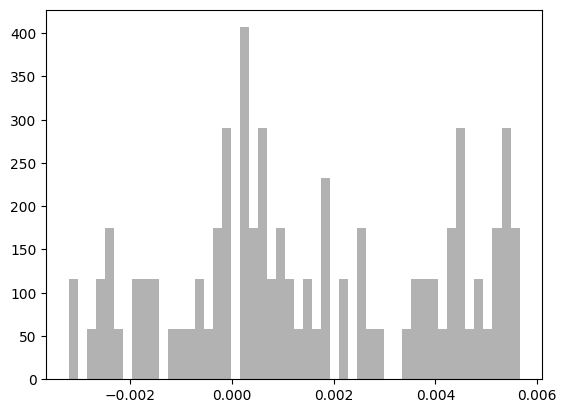

In [115]:
plt.hist(mean_u.dropna(), bins=50, density=True, alpha=0.6, color='grey')
plt.show()

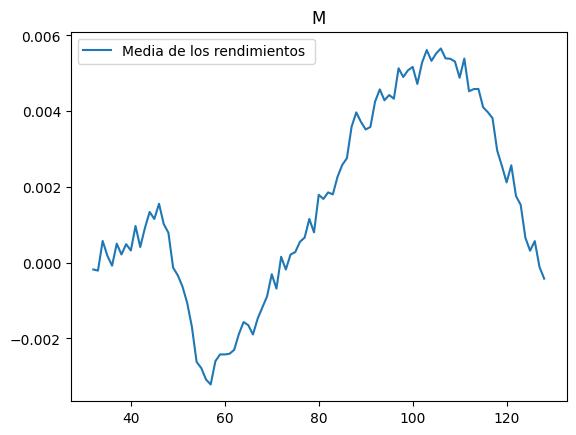

In [116]:
plt.plot(mean_u.dropna())
plt.legend(['Media de los rendimientos '])
plt.title('M')
plt.show()

In [118]:
mean_muestra = df['U'].mean()
desv_muestra = df['U'].std(ddof=1)

print(f"Media : {mean_muestra}")
print(f"Desv : {desv_muestra}")

Media : 0.000539688414376501
Desv : 0.009992580529958219
